# Counting faces with a Haar cascade

Tiny project. The point is to count how many faces are in an image using `cv2.CascadeClassifier` (the Haar cascade XML ships with OpenCV, no model download needed). Haar cascades are old — Viola-Jones is from 2001 — but they're still surprisingly reasonable on frontal, well-lit faces and they run instantly on CPU.

I'm not benchmarking this. I just want a working face counter that I can point at a handful of images.

In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../../data/sample_images")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(cascade_path)
print("cascade loaded:", not face_cascade.empty())

cascade loaded: True


In [2]:
def count_faces(img_bgr, scaleFactor=1.1, minNeighbors=5, minSize=(30,30)):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    # equalizing histogram helps a lot on under-exposed group photos
    gray = cv2.equalizeHist(gray)
    boxes = face_cascade.detectMultiScale(gray, scaleFactor=scaleFactor,
                                          minNeighbors=minNeighbors,
                                          minSize=minSize)
    return boxes

def draw(img_bgr, boxes):
    out = img_bgr.copy()
    for (x, y, w, h) in boxes:
        cv2.rectangle(out, (x, y), (x+w, y+h), (0, 220, 0), 2)
    cv2.putText(out, f"faces: {len(boxes)}", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 220, 0), 2)
    return out

## Demo on whatever images are around

I'm not curating a dataset. If `data/sample_images/` has anything, I run on the first three. If not, I synthesize an image with circular "blobs" that won't trigger the cascade — just so the notebook doesn't crash.

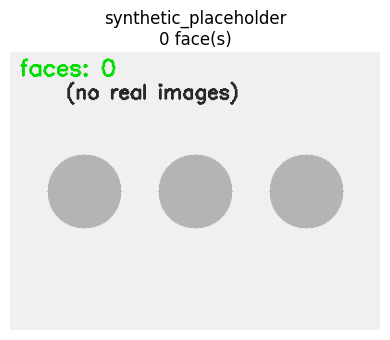

In [3]:
def _placeholder():
    img = np.full((300, 400, 3), 240, dtype=np.uint8)
    for cx, cy in [(80, 150), (200, 150), (320, 150)]:
        cv2.circle(img, (cx, cy), 40, (180, 180, 180), -1)
    cv2.putText(img, "(no real images)", (60, 50),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (40, 40, 40), 2)
    return img

paths = sorted([p for p in DATA.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}])[:3]
if not paths:
    images = [_placeholder()]
    names = ["synthetic_placeholder"]
else:
    images = [cv2.imread(str(p)) for p in paths]
    names = [p.name for p in paths]

fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 4))
if len(images) == 1: axes = [axes]
for ax, img, name in zip(axes, images, names):
    boxes = count_faces(img)
    drawn = draw(img, boxes)
    ax.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}\n{len(boxes)} face(s)")
    ax.axis("off")
plt.tight_layout(); plt.savefig(ART/"face_counts.png", dpi=110); plt.show()

## Notes

The cascade is sensitive to `scaleFactor` and `minNeighbors`. I'm using `(1.1, 5)` which is the OpenCV docs default. Crank `minNeighbors` up if you're getting false positives on textures (curtains, brick walls).

Realistically, for any serious face counting in 2026 you'd want MTCNN or a YOLO face model. But the Haar cascade is two lines of code and a free first pass, which is the whole point.